In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook
from matplotlib.colorbar import ColorbarBase
from numpy.linalg import cholesky

from scipy.integrate import quad, dblquad, quadrature
from scipy.interpolate import interp1d
import os

import seaborn as sns
import pandas as pd

#Plot param
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset']='dejavuserif'
plt.rcParams["figure.figsize"] = [15,10]
plt.rcParams["font.size"] = 30


#GPs
def cs2fromphi(element):
    return 1/(np.exp(element) +1)

def phifromsc2(element):
    return np.log(1/element - 1)

In [36]:
#units
MeV_to_fm_m1 = 1/197.3
GeV_to_fm = 5.068
MeV_to_GeV = 1e-3
MeV4_to_GeV_fm3 = (MeV_to_GeV**4)*GeV_to_fm**3

## Reading in lattice data

In [6]:
data = pd.read_csv("cs2_WB.dat",sep="\s+",header=None)
data_extracted = pd.read_csv("/home/luiza/masters_research/codes/gp/cs2_data_extrap/points_extracted",sep=",",header=None)

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_10920/1095654036.py:1: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv("cs2_WB.dat",sep="\s+",header=None)


In [7]:
lat_cs2 = data[[0,1,2]]
extract_cs2 = data_extracted[[0,1]]

In [8]:
lat_cs2.columns = ['T','cs2','error']
extract_cs2.columns = ['T_extract', 'cs2_extract']

In [9]:
# ax = plt.subplot()

# # Lattice mean
# ax.plot(lat_cs2['T'], lat_cs2['cs2'],c = 'black',ms='10',lw=5)
# #Lattice error

# gray_with_alpha = to_rgba('gray', 0.3)

# ax.fill_between(
#     lat_cs2['T'],
#     lat_cs2['cs2'] - lat_cs2['error'],
#     lat_cs2['cs2'] + lat_cs2['error'],
#     facecolor=gray_with_alpha,
#     label='WB (2025)'
# )

# ax.set_xlabel("T [MeV]")
# ax.set_ylabel(r"$c_s^2$")
   
# ax.patch.set_edgecolor('black')  
# ax.patch.set_linewidth('5') 
# ax.xaxis.set_tick_params(width=5,length=10) 
# ax.yaxis.set_tick_params(width=5,length=10)
# ax.yaxis.major.formatter._useMathText = True


# ax.legend(loc='lower right',framealpha = 0, 
#            frameon=False,fontsize=30,ncol=2)


In [10]:
lat_cs2.to_csv("data.dat", sep= ' ', index = False)
extract_cs2.to_csv("data_extracted.dat", sep= ',', index = False)

interp_func = interp1d(extract_cs2['T_extract'], extract_cs2['cs2_extract'], kind='linear') 


## GPs

In [11]:
def kernel_func(x1,x2,sigma,l):
    return(sigma*np.exp(-(x1-x2)**2/(2*l**2)))

In [12]:
T_sampling_range = np.linspace(120,700,700-120+1)
T_up = np.linspace(261,700,700-261+1)
GP_mean = lat_cs2.cs2
GP_mean_up = interp_func(T_up)

In [13]:
## GP hyperparameters ##
##################
l = 30
sigma = 10
##################

In [14]:
mean_data = np.concatenate([GP_mean, GP_mean_up])

def generate_sample():   
    k = []
    mean = [phifromsc2(el) for el in mean_data]
    for x1 in T_sampling_range:
        k_row = []
        for x2 in T_sampling_range:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_sampling_range))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

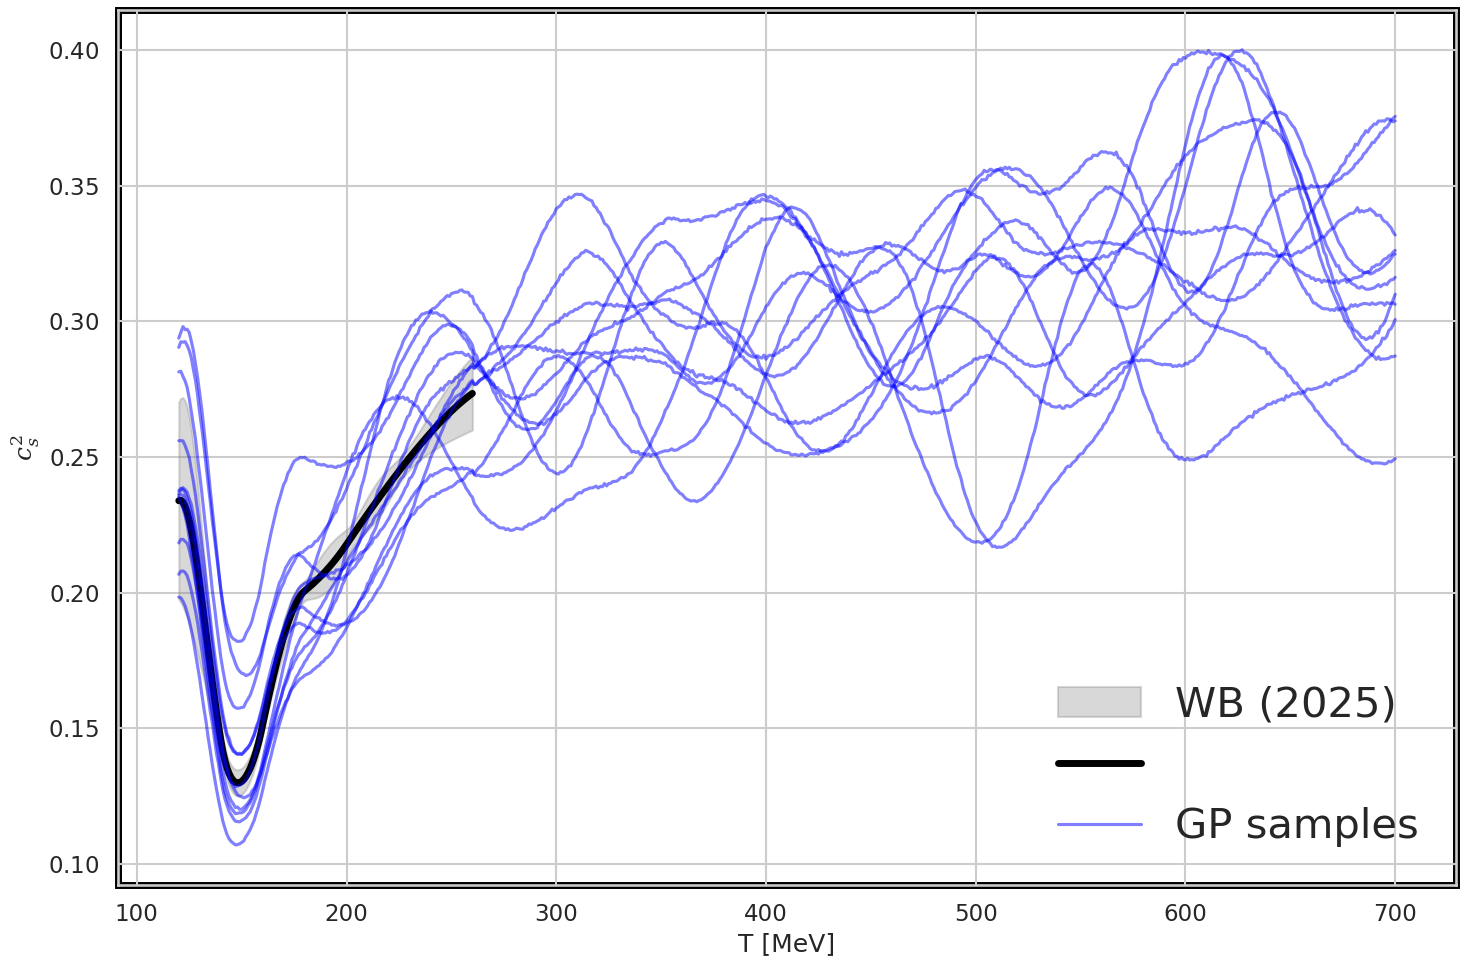

In [15]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

# Lattice error band
ax.fill_between(
    lat_cs2['T'],
    lat_cs2['cs2'] - lat_cs2['error'],
    lat_cs2['cs2'] + lat_cs2['error'],
    alpha=0.3,
    color='gray',
    label='WB (2025)'
)

# Lattice mean line
sns.lineplot(
    data=lat_cs2,
    x='T',
    y='cs2',
    ax=ax,
    color='black',
    linewidth=5,
    label=' '
)

for i in range(11):
    cs2_sample = generate_sample()
    
    ax.plot(
        T_sampling_range,
        cs2_sample,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('my_plot3.png')
plt.show()



## HRG

In [16]:
file_path = "/home/luiza/masters_research/codes/pdg-urqmd_v3.3+.dat"

if not os.path.isfile(file_path):
    print("Unable to open file")
    exit(1)

m_bosons = []
m_fermions = []
g_b = []
g_f = []

with open(file_path, "r") as file:
    for line in file:
        
        #removes whitespace characters, including spaces, tabs, and newlines
        line = line.strip() 
        
        if not line:
            continue  # skip empty lines

        values = line.split()

        if values[1][0].isalpha():
            try:
                mass = float(values[2])
                f_or_b = int(values[5])
                g = float(values[4])
                mass_mev = mass * 1e3  #MeV

                if f_or_b == 1:
                    m_fermions.append(mass_mev)
                    g_f.append(g)
                elif f_or_b == 0:
                    m_bosons.append(mass_mev)
                    g_b.append(g)
            except ValueError:
                continue  
        elif values[1][0].isdigit():
            continue  


In [17]:
def bose_einstein(k, T, mass):
    return 1.0/(np.exp(np.sqrt(k**2 + mass**2)/T) - 1)

def fermi_dirac(k, T, mass):
    return 1.0/(np.exp(np.sqrt(k**2 + mass**2)/T) + 1)

def pressure_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(6.0*(np.pi)**2))*(k**4)*fermi_dirac(k, T, mass)/(np.sqrt(k**2 + mass**2))
    elif eta == 0:
        return (g/(6.0*(np.pi)**2))*(k**4)*bose_einstein(k, T, mass)/(np.sqrt(k**2 + mass**2))
    else:
        raise ValueError("eta must be 0 or 1")

def energy_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*fermi_dirac(k, T, mass)
    elif eta == 0:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*bose_einstein(k, T, mass)

In [18]:
T_sw = 150 #MeV

def total_pressure(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(pressure_integrand, 0, 100000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(pressure_integrand, 0, 100000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

def total_energy(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(energy_integrand, 0, 100000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(energy_integrand, 0, 100000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

P_sw = total_pressure(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
e_sw = total_energy(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
s_sw =  (P_sw + e_sw)/T_sw #MeV^3

print(P_sw*MeV4_to_GeV_fm3)

#print(total_energy(T, m_fermions, g_f, m_bosons, g_b)/T**4)
#print(total_pressure(T, m_fermions, g_f, m_bosons, g_b)/T**4)
#print(entropy/T**3)

5.254009465837945e-11


## Thermodynamics

In [19]:
cs2_sample_list = generate_sample()

cs2_interp = interp1d(T_sampling_range, cs2_sample_list)

T_range_up = np.round(np.arange(120, 700 + 0.001, 0.1), 10)
T_range_down = np.round(np.arange(0, 119.9 + 0.001, 0.1), 10)
T_total = np.round(np.arange(0, 700 + 0.001, 0.1), 10)

In [20]:
#possible ways to extrapolate to zero

# def s_down_function(T, T0, s0):
#     t = T / T0
#     return s0 * (3 * t**2 - 2 * t**3)

# def s_down_prime(T, T0, s0):
#     return s0 * (6*T/(T0**2) - 6 * (T**2)/(T0**3))

def compute_cubic_coeffs(T0, s0, m1):
    A = np.array([
        [T0**3, T0**2],
        [3*T0**2, 2*T0]
    ])
    Y = np.array([s0, m1])
    a, b = np.linalg.solve(A, Y)
    return a, b

def s_down_function(T, T0, s0, m1):
    x = T / T0
    h00 = 3 * x**2 - 2 * x**3
    h10 = x**3 - 2 * x**2 + x
    return s0 * h00 + (T0 * m1 - 6 * s0) * h10

In [21]:
#s upwards

def s_integrand(T, cs2_interp):
    return 1 / (T * cs2_interp(T))
    
def entropy_up(s_sw, T_sw, cs2_interp, T_range_up):
    s_up = []
        
    for T in T_range_up:
        if T < T_sw:
            integral, _ = quad(s_integrand, T, T_sw, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            s = s_sw * np.exp(-integral)
        elif T > T_sw:
            integral, _ = quad(s_integrand, T_sw, T, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            s = s_sw * np.exp(integral)
        else:
            s = s_sw
        s_up.append(s)
    return s_up

s_up = entropy_up(s_sw, T_sw, cs2_interp, T_range_up)

In [22]:
s_up_interp = interp1d(T_range_up, s_up, kind='cubic', fill_value="extrapolate")

T0 = T_range_up[0]
delta_T = 1e-2
ds_dT0 = (s_up_interp(T0 + delta_T) - s_up_interp(T0 - delta_T)) / (2 * delta_T)
s0 = s_up[0]

cs2_match = cs2_sample_list[0]



n = 1 / cs2_match
a_s = s0 / T0**n

# Define s_low
def s_down(T):
    return a_s*T**n

entropy =  np.concatenate([s_down(T_range_down), s_up])

In [23]:
s_interp = interp1d(T_total, entropy)

T_test = np.round(np.arange(100, 140 + 0.001, 0.1), 10)

sT_vec = []
for T in T_total:
    sT_vec.append(s_interp(T)*T)

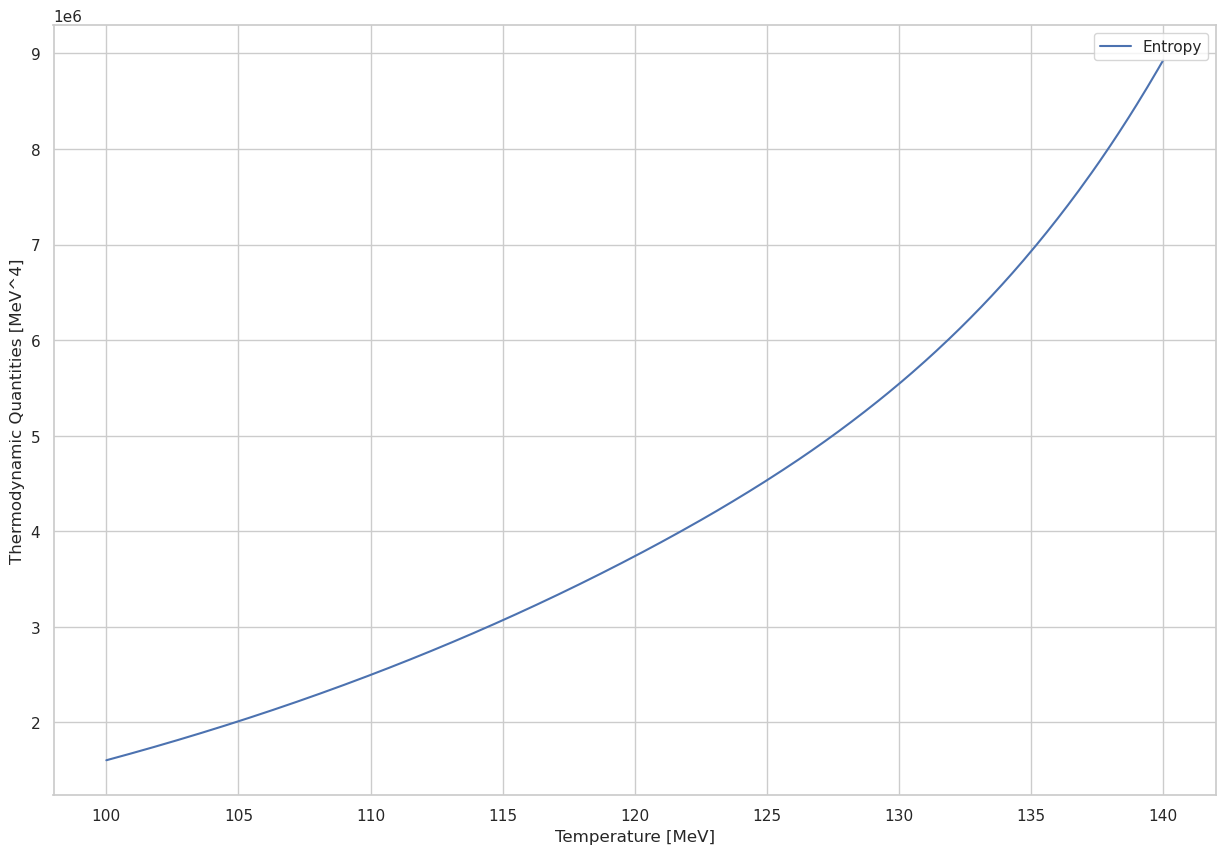

In [24]:
df = pd.DataFrame({'T': T_test, 'Entropy': s_interp(T_test)})

sns.set(style="whitegrid")
sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Thermodynamic Quantities [MeV^4]')
plt.legend()
plt.savefig('eos.png')
plt.show()

In [25]:
#pressure downwards

def P_integrand(T, s_interp):
    return s_interp(T)

def pressure_integral(P_sw, T_sw, T_vec, s_interp):
    pressure = []
    for T in T_vec:
        if T < T_sw:
            integral, _ = quad(P_integrand, T, T_sw, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw - integral
        elif T > T_sw:
            integral, _ = quad(P_integrand, T_sw, T, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw + integral
        else:
            p = P_sw
        pressure.append(p)
    return pressure

In [26]:
#pressure upwards

P_up = pressure_integral(P_sw, T_sw, T_range_up, s_interp)

T0 = T_range_up[0]
p0 = P_up[0]
a_p = p0 / T0**3

P_down = a_p * T_range_down**3

pressure = np.concatenate([P_down, P_up])

P_interp = interp1d(T_total, pressure)

In [27]:
#energy upwards

def energy(s, P, T_vec):
    energy_vec = []
    for T in T_vec:
        energy_vec.append(s(T)*T - P(T))
    return energy_vec

e_up = energy(s_interp, P_interp, T_range_up)

In [28]:
#energy downwards

T0 = T_range_up[0]
e0 = e_up[0]
a_e = e0 / T0**4

e_down = a_e * T_range_down**4

energy = np.concatenate([e_down, e_up])

e_interp = interp1d(T_total, energy)

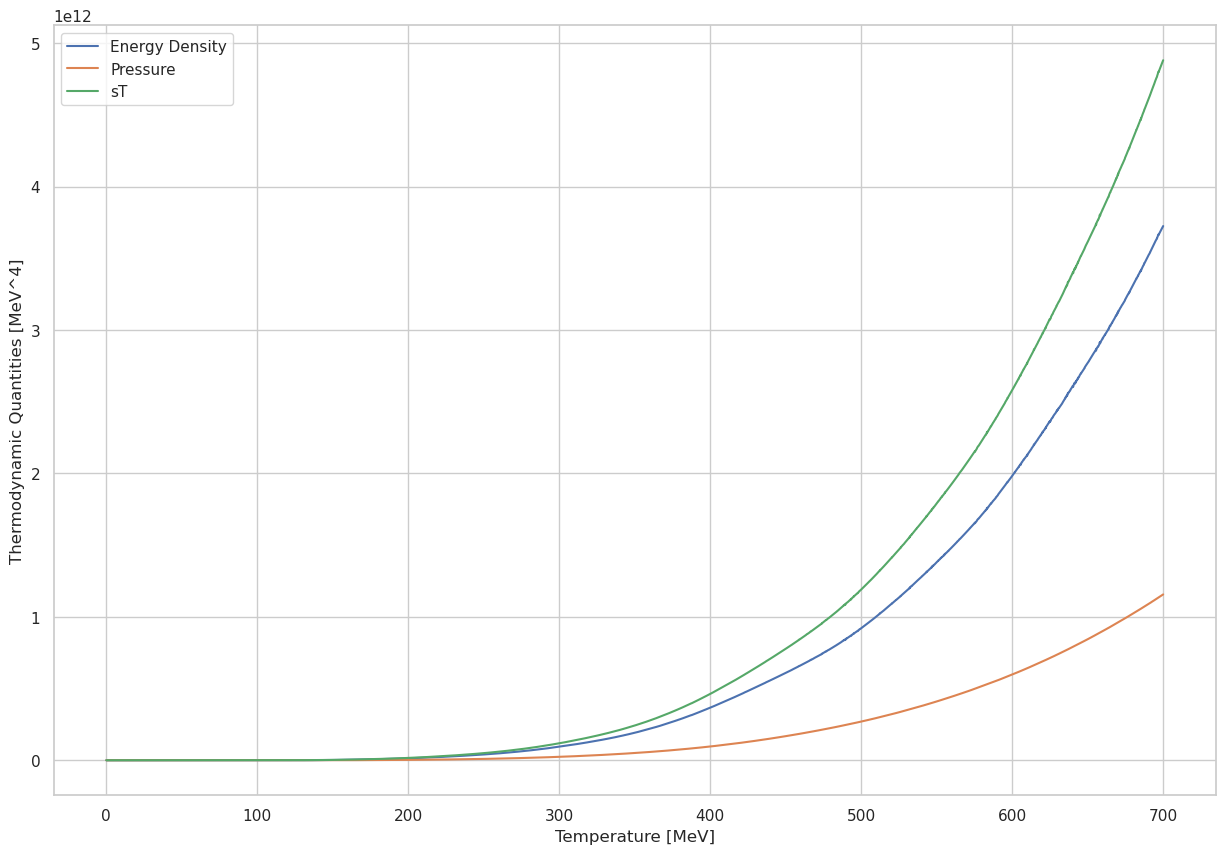

In [29]:
df = pd.DataFrame({'T': T_total, 'Entropy': s_interp(T_total), 'Energy': e_interp(T_total), 
                   'Pressure': P_interp(T_total), 'sT': sT_vec})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='Energy', label='Energy Density')
sns.lineplot(data=df, x='T', y='Pressure', label='Pressure')
sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Thermodynamic Quantities [MeV^4]')
plt.legend()
plt.savefig('eos.png')
plt.show()

In [ ]:
#cs2_vector

cs2_down = []
cs2_up = []

for T in T_range_down:
    cs2_down.append(cs2_match)
    
cs2_vec = np.concatenate([cs2_down, cs2_interp(T_range_up)])


7001


In [38]:
with open("eos.dat", "w") as f:
    for e, T, p, cs2 in zip(e_interp(T_total), T_total, P_interp(T_total), cs2_vec):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} \n")

with open("eos_all.dat", "w") as f:
    for T, e, p, s, cs2 in zip(T_total, e_interp(T_total), P_interp(T_total), s_interp(T_total), cs2_vec):
        f.write(f"{T} {e*MeV4_to_GeV_fm3} {p*MeV4_to_GeV_fm3} {s*(1/hbarc**3)} {cs2} \n")

# with open("check.dat", "w") as f:
#     for T, s, p, i in zip(T_range, s_interp(T_range), P_interp(T_range), integral_vec):
#               f.write(f"{T*} {s} {p} {i} \n")

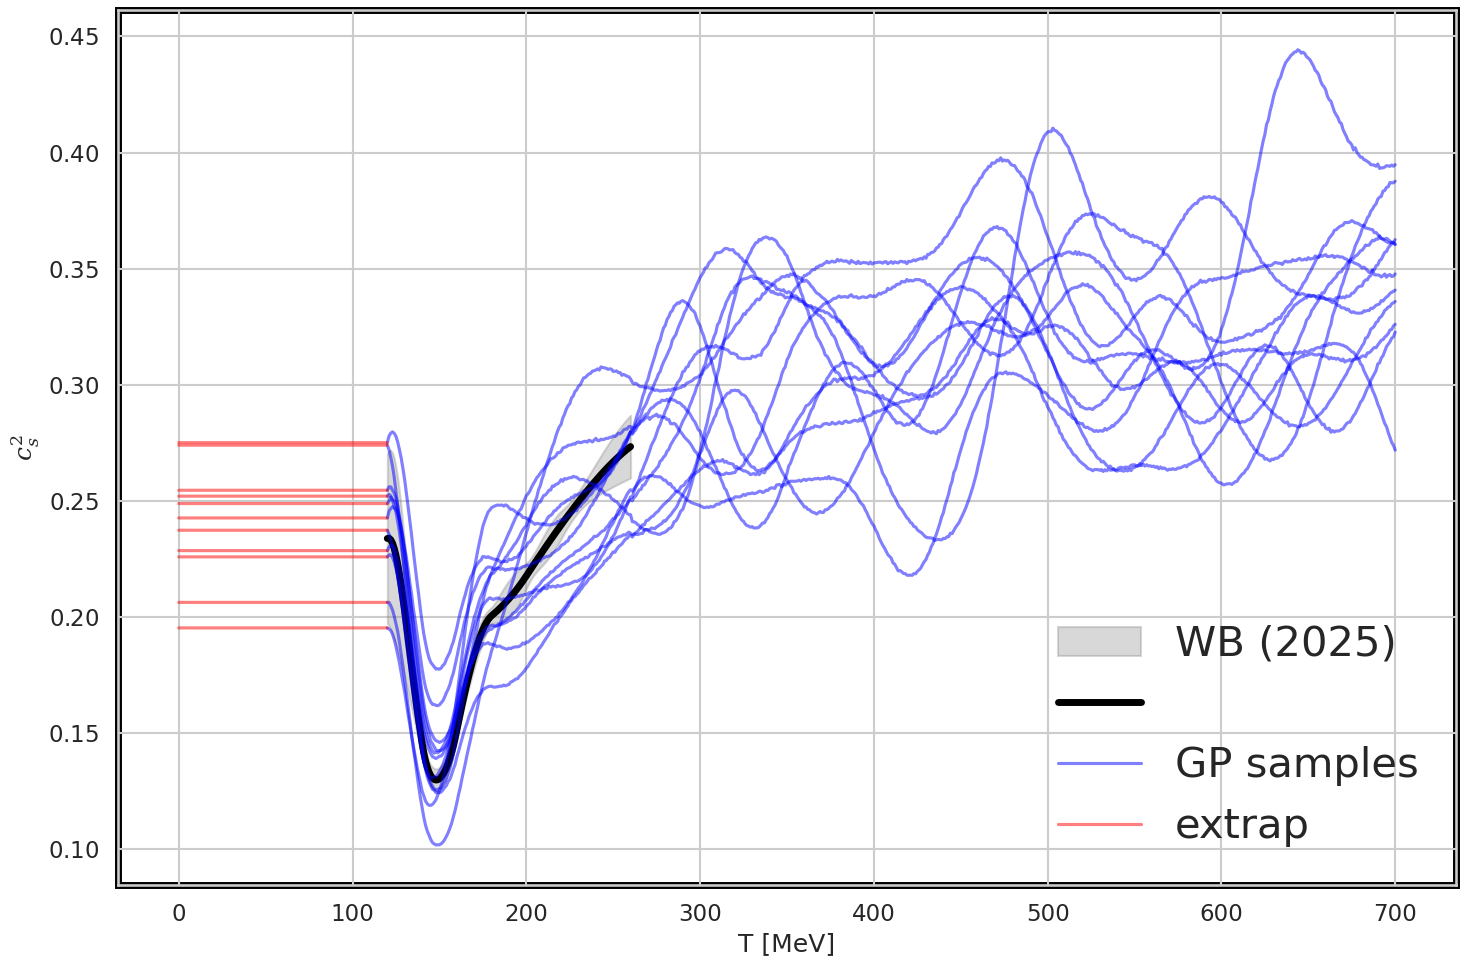

In [32]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

# Lattice error band
ax.fill_between(
    lat_cs2['T'],
    lat_cs2['cs2'] - lat_cs2['error'],
    lat_cs2['cs2'] + lat_cs2['error'],
    alpha=0.3,
    color='gray',
    label='WB (2025)'
)

# Lattice mean line
sns.lineplot(
    data=lat_cs2,
    x='T',
    y='cs2',
    ax=ax,
    color='black',
    linewidth=5,
    label=' '
)

for i in range(11):
    cs2_sample = generate_sample()
    cs2_match = cs2_sample[0]
    cs2_plot = []

    for T in T_range_down:
        cs2_plot.append(cs2_match)
    
    ax.plot(
        T_sampling_range,
        cs2_sample,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    ax.plot(
        T_range_down,
        cs2_plot,
        color='red',
        alpha=0.5,
        label='extrap' if i == 0 else None      
    )

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('my_plot3.png')
plt.show()

